# Dish Localization

Fine-tunes YOLOv8n on food tray dataset using GPU.

### Config

In [1]:
ZIP_PATH = "/content/YOLOlabels.zip"

### import libraries

In [11]:
import subprocess
subprocess.run(["pip", "install", "ultralytics", "--quiet"])

import yaml
import shutil
import random
import cv2
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path
from ultralytics import YOLO
from google.colab import files

### Extract data from ZIP file

In [4]:
import zipfile, shutil
from pathlib import Path

extract_dir = Path("/content/YOLOlabels")
if extract_dir.exists():
    shutil.rmtree(extract_dir)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall("/content/")

print("Extracted. Contents:")
for p in sorted(Path("/content/YOLOlabels").rglob("*"))[:20]:
    print(f"  {p}")

Extracted. Contents:


### Config

In [15]:
DATASET_YAML = "/content/YOLOlabels/dataset.yaml"
MODEL        = "yolov8n.pt"
EPOCHS       = 100
BATCH        = 16
IMG_SIZE     = 640
PROJECT      = "/content/runs"
RUN_NAME     = "food_tray_v1"
CONF         = 0.35
N_PREVIEW    = 5

CLASS_NAMES  = ["food", "rice", "soup", "meatless soup"]
CLASS_COLORS = {
    0: (56,  182, 255),
    1: (56,  255, 120),
    2: (255, 100,  56),
    3: (200,  56, 255),
}

### Verify Dataset

In [13]:
def verify_dataset(yaml_path):
    data = yaml.safe_load(open(yaml_path))

    # Fix path to Colab absolute path
    data["path"] = "/content/YOLOlabels"
    with open(yaml_path, "w") as f:
        yaml.dump(data, f)

    base       = Path(data["path"])
    train_imgs = list((base / data["train"]).glob("*.*"))
    val_imgs   = list((base / data["val"]).glob("*.*"))
    train_lbls = list((base / data["train"].replace("images", "labels")).glob("*.txt"))
    val_lbls   = list((base / data["val"].replace("images", "labels")).glob("*.txt"))

    print("\nDataset summary")
    print(f"  classes      : {data['names']}")
    print(f"  train images : {len(train_imgs)}")
    print(f"  train labels : {len(train_lbls)}")
    print(f"  val   images : {len(val_imgs)}")
    print(f"  val   labels : {len(val_lbls)}")

    if len(train_imgs) == 0:
        raise RuntimeError("No training images found — check your zip structure.")
    if len(train_imgs) != len(train_lbls):
        print(f"  [warn] image/label count mismatch in train set")

    print("\nDataset OK.")

### Train

In [14]:
def train():
    import torch
    print(f"\nGPU : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NOT FOUND — check Runtime type'}")

    model = YOLO(MODEL)

    model.train(
        data      = DATASET_YAML,
        epochs    = EPOCHS,
        batch     = BATCH,
        imgsz     = IMG_SIZE,
        device    = 0,
        project   = PROJECT,
        name      = RUN_NAME,
        exist_ok  = True,
        freeze    = 10,
        optimizer = "AdamW",
        lr0       = 0.001,
        lrf       = 0.01,
        patience  = 15,
        hsv_h     = 0.015,
        hsv_s     = 0.7,
        hsv_v     = 0.4,
        fliplr    = 0.5,
        translate = 0.1,
        scale     = 0.5,
        mosaic    = 0.5,
        verbose   = True,
        plots     = True,
    )

    best = Path(PROJECT) / RUN_NAME / "weights" / "best.pt"
    print(f"\nBest model saved to: {best}")
    return best

### Evaluate

In [16]:
def evaluate(model_path, dataset_yaml):
    model   = YOLO(model_path)
    metrics = model.val(data=dataset_yaml, device=0, verbose=True)

    print("\nResults")
    print(f"  mAP50     : {metrics.box.map50:.3f}  (target > 0.70)")
    print(f"  mAP50-95  : {metrics.box.map:.3f}")
    print(f"  Precision : {metrics.box.mp:.3f}")
    print(f"  Recall    : {metrics.box.mr:.3f}")

    if   metrics.box.map50 >= 0.70: print("\n  Good — ready to deploy.")
    elif metrics.box.map50 >= 0.50: print("\n  Acceptable. More labeled images will improve results.")
    else:                           print("\n  Low accuracy. Collect more labeled images.")

    return metrics

In [17]:
def show_training_curves(run_dir):
    for plot_name in ["results.png", "confusion_matrix.png", "val_batch0_pred.jpg"]:
        plot = run_dir / plot_name
        if plot.exists():
            fig, ax = plt.subplots(figsize=(14, 6))
            ax.imshow(mpimg.imread(str(plot)))
            ax.axis("off")
            ax.set_title(plot_name)
            plt.tight_layout()
            plt.show()

### Detection preview on test images

In [18]:
def draw_boxes(image, boxes):
    for box in boxes:
        cls_id          = int(box.cls[0])
        conf            = float(box.conf[0])
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        color           = CLASS_COLORS.get(cls_id, (255, 255, 255))
        label           = f"{CLASS_NAMES[cls_id]} {conf:.0%}"

        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
        (tw, th), _  = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
        cv2.rectangle(image, (x1, y1 - th - 8), (x1 + tw + 4, y1), color, -1)
        cv2.putText(image, label, (x1 + 2, y1 - 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
    return image

In [19]:
def detection_preview(model_path, val_dir, conf=0.35, n=5):
    model      = YOLO(model_path)
    image_exts = {".jpg", ".jpeg", ".png", ".bmp"}
    all_imgs   = [p for p in Path(val_dir).rglob("*") if p.suffix.lower() in image_exts]

    if not all_imgs:
        print(f"No images in {val_dir}")
        return

    samples = random.sample(all_imgs, min(n, len(all_imgs)))

    for img_path in samples:
        image   = cv2.imread(str(img_path))
        results = model(image, conf=conf, verbose=False)[0]
        boxes   = results.boxes

        print(f"\n{img_path.name}  —  {len(boxes)} detection(s)")
        for box in boxes:
            print(f"  {CLASS_NAMES[int(box.cls[0])]:<20} {float(box.conf[0]):.1%}")

        annotated = draw_boxes(image.copy(), boxes)
        plt.figure(figsize=(10, 6))
        plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        plt.title(img_path.name)
        plt.axis("off")
        plt.tight_layout()
        plt.show()

### Download model

In [20]:
def download_model(model_path, run_dir):
    bundle = Path("/content/model_export")
    bundle.mkdir(exist_ok=True)

    shutil.copy2(model_path, bundle / "best.pt")

    for plot in ["results.png", "confusion_matrix.png", "val_batch0_pred.jpg"]:
        src = run_dir / plot
        if src.exists():
            shutil.copy2(src, bundle / plot)

    zip_path = "/content/food_tray_model"
    shutil.make_archive(zip_path, "zip", bundle)

    print("Downloading food_tray_model.zip ...")
    files.download(zip_path + ".zip")


Dataset summary
  classes      : ['food', 'rice', 'soup', 'meatless soup', 'drink']
  train images : 109
  train labels : 109
  val   images : 28
  val   labels : 28

Dataset OK.

GPU : Tesla T4
Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/YOLOlabels/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300

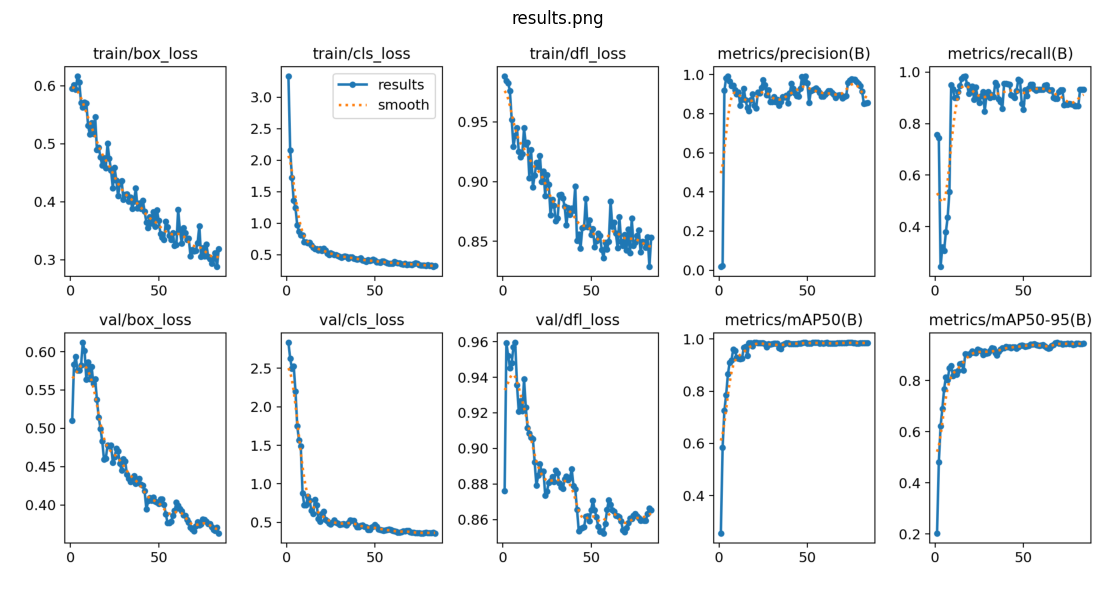

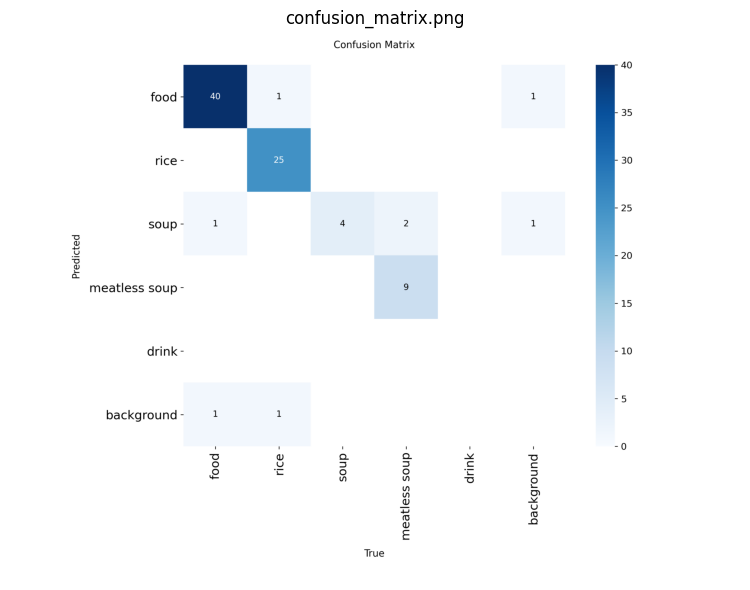

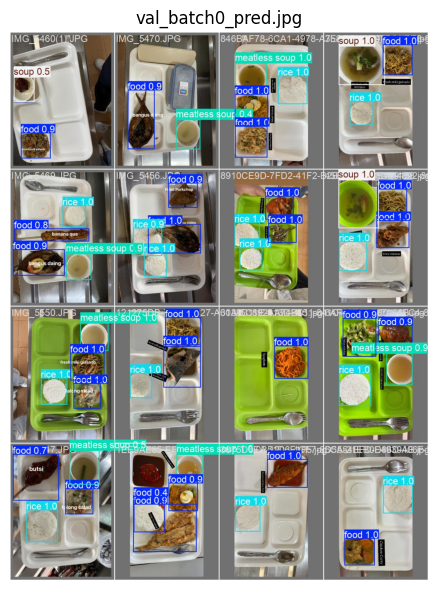


April 13, 2026 Plate(3).jpg  —  3 detection(s)
  rice                 95.6%
  food                 94.6%
  soup                 94.4%


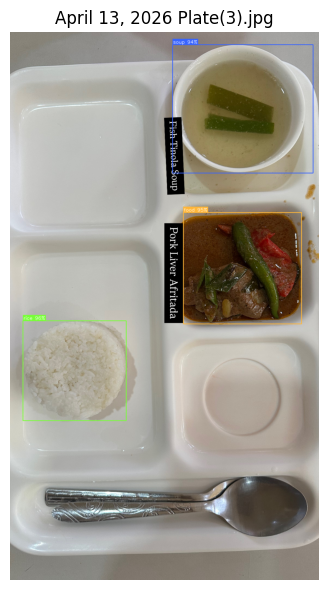


846BAF78-6CA1-4978-A758-BCA6E93B4A3A.jpg  —  4 detection(s)
  rice                 98.0%
  meatless soup        97.8%
  food                 97.2%
  food                 96.3%


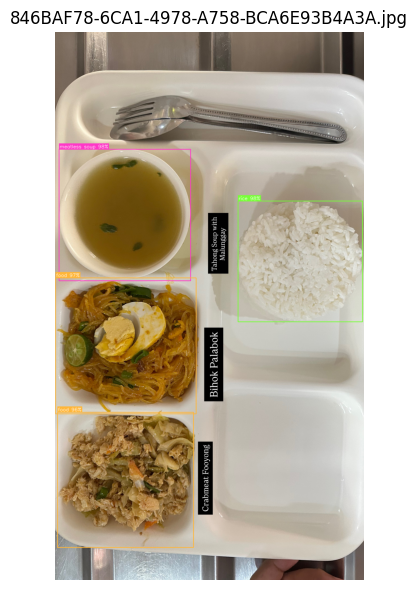


121275DB-716D-4F27-A61A-5C892AA74B45.jpg  —  3 detection(s)
  rice                 97.9%
  food                 97.5%
  food                 96.8%


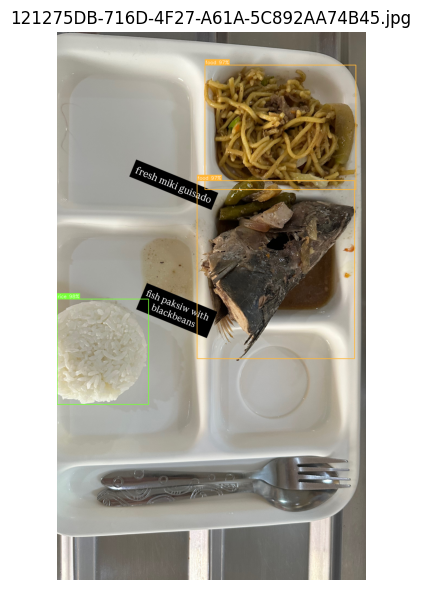


F0E9897A-A93C-48F1-B32F-F9971C6AD709.jpg  —  3 detection(s)
  soup                 99.8%
  food                 98.9%
  rice                 95.1%


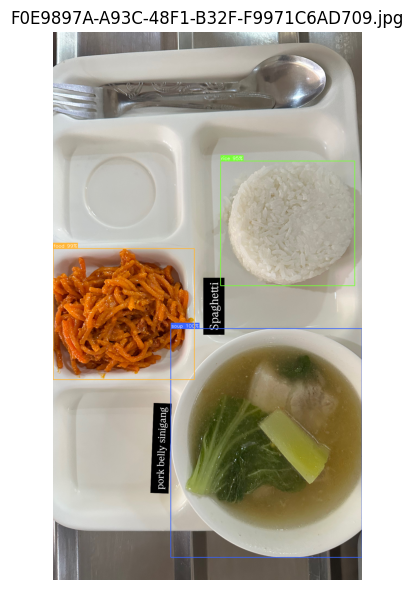


IMG_5470.JPG  —  1 detection(s)
  food                 87.0%


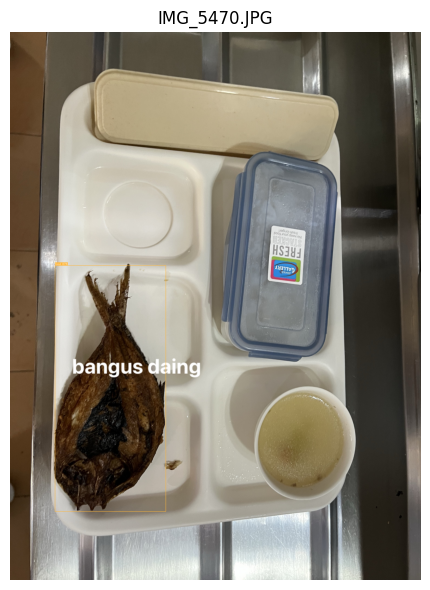

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
verify_dataset(DATASET_YAML)
best_model_path = train()
run_dir         = Path(PROJECT) / RUN_NAME
evaluate(best_model_path, DATASET_YAML)
show_training_curves(run_dir)
detection_preview(best_model_path, "/content/YOLOlabels/images/val", conf=CONF, n=N_PREVIEW)
download_model(best_model_path, run_dir)

In [10]:
# train_imgs = list(Path("/content/YOLOlabels/images/train").glob("*.*"))
# val_imgs   = list(Path("/content/YOLOlabels/images/val").glob("*.*"))
# print(f"Train: {len(train_imgs)}")
# print(f"Val:   {len(val_imgs)}")

Train: 109
Val:   28
